# 02 – Signallabor: Gebäudespezifische Signalverarbeitung
**Netzdienlichkeit · PEXL · Experiment C**

Ziel: Dasselbe externe Signal an unterschiedliche thermische Gebäudeeigenschaften anpassen und die resultierenden Aktivierungsverläufe vergleichen. Dieses Notebook ist eigenständig ausführbar; es benötigt nicht die Ausführung von Notebook 01.

**Bedienung:** Lege `signallabor_data.csv` neben beide Notebooks. Öffne das Notebook in Jupyter oder VS Code, wähle einen Python-Kernel und führe die Zellen von oben nach unten mit Shift+Enter aus. Benötigt werden pandas, numpy und matplotlib (`%pip install pandas numpy matplotlib`, falls nötig). Ändere nur die als **EXPERIMENT** gekennzeichneten Parameter und beantworte die Leitfragen in Markdown. Keine eigene Programmierung erforderlich.

Ein Signal $s(t)$ zwischen 0 und 1 beschreibt die **angeforderte zusätzliche Flexibilitätsnutzung**. 0 bedeutet keine zusätzliche Aktivierung (kein generelles Verbrauchsverbot), 1 maximale Aktivierung innerhalb der verfügbaren Flexibilität. Es ist weder eine direkte Leistungsanforderung in kW noch ein Nachweis tatsächlicher Lastverschiebung.

## 1. Ausgangsdaten
| Auswahl | Größe | Freigabe bei |
|---|---|---|
| wind | Onshore-Winderzeugung [MW; Einheit gemäß Generation-by-Type-Konvention] | hohen Werten |
| exaa | Day-Ahead EXAA [€/MWh] | niedrigen Werten |
| mc | Day-Ahead MC [€/MWh] | niedrigen Werten |
| co2 | Strommix-THG-Intensität (LCA) [g CO₂eq/kWh] | niedrigen Werten |
| load_error | Istlast minus Day-Ahead-Prognose [MW] | negativen Werten |

Datengrundlage: bereitgestellte ENTSO-E-Jahresblätter, `exaa.csv`, stündliche MC-Spalten aus `Day Ahead Preise_AT_20-24 - FlexSignale.xlsx`, Electricity Map 2021/2022 (LCA), `Day-ahead Forecast vs. Actual Load [MW].csv`. Die vorhandenen binären Spalten werden nicht verwendet.

**Zeitachse (Draft):** 2021 und 2022, jeweils 8760 Werte ohne Fehlwerte. Wind wird in ursprünglicher chronologischer Reihenfolge übernommen (inkl. doppelter lokaler Herbststunde, ohne leere Schlusszeile). Preis und Lastfehler liegen bereits als 8760-Stunden-Reihen vor; CO₂ liegt in UTC vor. Der gemeinsame Modellzeitstempel ist eine synthetische Stundenachse, keine nachgewiesene zeitzonenrichtige Synchronisation. Vergleiche hier nur Signalstatistiken; vor zeitgenauer gemeinsamer Simulation oder Kreuzkorrelation muss die Zeitbasis mit PEExcel abgeglichen werden. 2020 (Schaltjahr und abweichendes CO₂-Schema) sowie weitere Jahre sind in diesem Draft nicht enthalten.

**Interpretation:** Lastprognosefehler werden rückblickend ausgewertet; sie sind zum Day-Ahead-Zeitpunkt nicht bekannt. Niedrige Preise, niedrige THG-Intensität und hohe Windproduktion sind unterschiedliche Zielgrößen und kein Beleg für lokale Netzentlastung.

In [50]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

data = pd.read_csv(Path("signallabor_data.csv"), parse_dates=["model_timestamp"])
assert data.groupby("year").size().eq(8760).all()
assert not data.isna().any().any()
info = {
    "wind": ("Wind Onshore", "MW", "high"),
    "exaa": ("EXAA", "EUR/MWh", "low"),
    "mc": ("Market Coupling", "EUR/MWh", "low"),
    "co2": ("THG-Intensität LCA", "g CO₂eq/kWh", "low"),
    "load_error": ("Istlast − Prognose", "MW", "low"),
}
display(data.groupby("year").size().rename("Stunden"))

year
2021    8760
2022    8760
Name: Stunden, dtype: int64

## 1. Ausgangssignal aus Notebook 01

Übertrage deine gewählten Parameter aus Notebook 01. Die Signalberechnung ist identisch. Bei Quantil-Ramps ist `share = (Vollaktivierungsanteil, Aktivierungsbeginn)`. Das Fenster enthält die aktuelle Stunde, frühere und spätere Stunden. Für `fixed` ist `threshold` bei kontinuierlicher Aktivierung `(keine, volle Aktivierung)` in Originaleinheiten.

In [51]:
def rolling_quantile(x, q, window):
    before, after = window
    if not all(isinstance(h, (int, np.integer)) and h >= 0 for h in window):
        raise ValueError("window: zwei nichtnegative ganze Stundenwerte")
    if not 1 <= before + after < len(x):
        raise ValueError("window: Summe der Stunden muss zwischen 1 und 8759 liegen")
    padded = pd.Series(np.r_[x.to_numpy(dtype=float), np.full(after, np.nan)])
    return pd.Series(padded.rolling(before + after + 1, min_periods=1)
                     .quantile(q).shift(-after).iloc[:len(x)].to_numpy(), index=x.index)


def reference(x, method, q, window):
    if method == "annual":
        return pd.Series(x.quantile(q), index=x.index)
    if method == "monthly":
        return x.groupby(x.index.month).transform(lambda a: a.quantile(q))
    if method == "rolling":
        return rolling_quantile(x, q, window)
    raise ValueError("method: fixed, annual, monthly oder rolling")


def activation_curve(a, activation):
    a = np.clip(a, 0, 1)
    if activation == "linear":
        return a
    if activation == "smoothstep":
        return a*a*(3-2*a)
    if activation == "sigmoid":
        # Rescaled logistic: exactly 0 and 1 at the ramp endpoints.
        f = lambda v: 1/(1+np.exp(-10*(v-.5)))
        return (f(a)-f(0))/(f(1)-f(0))
    raise ValueError("activation: binary, linear, sigmoid oder smoothstep")


def make_signal(year, source, method="annual", share=.30,
                window=(0,24), threshold=0, activation="binary"):
    x = data.loc[data.year.eq(year)].set_index("model_timestamp")[source].sort_index()
    if len(x) != 8760:
        raise ValueError("Modelljahr mit 8760 Stunden erforderlich")
    # Intern: höhere Werte sind stets günstiger.
    direction = 1 if info[source][2] == "high" else -1
    z = direction*x
    if activation == "binary":
        if method == "fixed":
            low = pd.Series(direction*float(threshold), index=x.index)
        else:
            if not 0 < share < 1:
                raise ValueError("share muss zwischen 0 und 1 liegen")
            low = reference(z, method, 1-share, window)
        high = low.copy()
        s = (z > low).astype(float)
    else:
        if method == "fixed":
            # threshold = (keine Aktivierung, volle Aktivierung), in Originaleinheit
            a, b = threshold
            if not direction*a < direction*b:
                raise ValueError("threshold: (keine, volle Aktivierung), Richtung beachten")
            low = pd.Series(direction*a, index=x.index)
            high = pd.Series(direction*b, index=x.index)
        else:
            full, start = share
            if not 0 < full < start < 1:
                raise ValueError("share: (Vollaktivierungsanteil, maximaler Aktivierungsanteil)")
            low = reference(z, method, 1-start, window)
            high = reference(z, method, 1-full, window)
        width = high-low
        # Degenerate quantiles: use a strict binary threshold where both coincide.
        a = ((z-low)/width.where(width>0)).where(width>0, (z>low).astype(float))
        s = activation_curve(a, activation)
    if source == "load_error":
        s = s.where(x < 0, 0)
    return x, direction*low, direction*high, s.astype(float).clip(0,1)


def periods(s, cutoff=.5):
    state = (s >= cutoff).astype(int)
    return state.groupby(state.ne(state.shift()).cumsum()).agg(state="first", hours="size")


def stats(s, cutoff=.5):
    r = periods(s, cutoff)
    on, off = r.loc[r.state.eq(1),"hours"], r.loc[r.state.eq(0),"hours"]
    return pd.Series({
        "Mittlerer Aktivierungsgrad [%]": 100*s.mean(),
        "Äquivalente Vollaktivierungsstunden [h]": s.sum(),
        "Stunden mit Aktivierung > 0 [h]": (s>0).sum(),
        "Stunden mit Aktivierung ≥ 0,9 [h]": (s>=.9).sum(),
        f"Stunden mit Aktivierung ≥ {cutoff:g} [h]": (s>=cutoff).sum(),
        f"Anteil Stunden ≥ {cutoff:g} [%]": 100*(s>=cutoff).mean(),
        "Aktivierungsphasen": len(on),
        "Mittlere Aktivierungsdauer [h]": on.mean(),
        "Median Aktivierungsdauer [h]": on.median(),
        "Mittlere Nichtaktivierungsdauer [h]": off.mean(),
        "Median Nichtaktivierungsdauer [h]": off.median(),
        "Längste Nichtaktivierung [h]": off.max(),
        "Mittlere absolute Änderung je Stunde": s.diff().abs().mean(),
    })


def detail(s, interval):
    result = s.loc[interval[0]:interval[1]]
    if result.empty:
        raise ValueError("Der Zeitraum liegt außerhalb des Modelljahres.")
    return result


def visualize(x, low, high, s, source, interval, cutoff=.5):
    d = detail(s, interval)
    fig, axes = plt.subplots(2,1,figsize=(12,5),sharex=True)
    axes[0].plot(d.index,x.loc[d.index],label=info[source][0])
    axes[0].plot(d.index,low.loc[d.index],"--",label="Schwelle: keine Aktivierung")
    if not low.equals(high):
        axes[0].plot(d.index,high.loc[d.index],":",label="Schwelle: volle Aktivierung")
    axes[0].set_ylabel(info[source][1]); axes[0].legend()
    axes[1].step(d.index,d,where="post",color="tab:green",label="Aktivierung")
    axes[1].fill_between(d.index,0,d.to_numpy(),step="post",alpha=.18,color="tab:green")
    axes[1].set(ylim=(-.03,1.03),ylabel="Aktivierung [0–1]"); axes[1].legend()
    fig.autofmt_xdate(); fig.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(12,3))
    im = ax.imshow(s.to_numpy().reshape(365,24).T,aspect="auto",origin="lower",vmin=0,vmax=1,cmap="Greens",extent=(.5,365.5,-.5,23.5))
    ax.set(xlabel="Tag im Modelljahr",ylabel="Stunde",title="Aktivierung im Jahresverlauf")
    fig.colorbar(im,ax=ax); plt.show()
    fig,ax=plt.subplots(figsize=(10,3))
    (100*s.groupby(s.index.month).mean()).plot.bar(ax=ax)
    ax.set(xlabel="Monat",ylabel="Mittlere Aktivierung [%]",ylim=(0,100)); plt.show()
    r=periods(s,cutoff)
    fig,ax=plt.subplots(figsize=(9,3))
    for state,label in [(1,f"Aktivierung ≥ {cutoff:g}"),(0,f"Aktivierung < {cutoff:g}")]:
        v=r.loc[r.state.eq(state),"hours"]
        if len(v): ax.hist(v,bins=np.geomspace(1,max(2,r.hours.max()+1),20),alpha=.5,label=label)
    ax.set(xscale="log",xlabel="Phasendauer [h, logarithmisch]",ylabel="Anzahl"); ax.legend(); plt.show()


def compare(signals, interval, cutoff=.5):
    display(pd.DataFrame({name:stats(s,cutoff) for name,s in signals.items()}).round(2))
    df=pd.DataFrame(signals)
    fig,ax=plt.subplots(figsize=(12,4))
    detail(df,interval).plot(ax=ax,drawstyle="steps-post",alpha=.8)
    ax.set(ylim=(-.03,1.03),ylabel="Aktivierung [0–1]",title="Detailvergleich"); plt.show()
    fig,ax=plt.subplots(figsize=(10,3))
    (100*df.groupby(df.index.month).mean()).plot.bar(ax=ax)
    ax.set(xlabel="Monat",ylabel="Mittlere Aktivierung [%]",ylim=(0,100)); plt.show()
    fig,ax=plt.subplots(figsize=(10,3))
    for name,s in signals.items():
        ax.hist(s,bins=np.linspace(0,1,21),histtype="step",linewidth=1.7,label=name, alpha=0.8)
    ax.set(xlabel="Aktivierung",ylabel="Stunden",title="Verteilung der Aktivierungsgrade"); ax.legend(); plt.show()


def export_signal(s, year, name, parameters, prefix):
    assert len(s)==8760 and s.notna().all() and s.between(0,1).all()
    folder=Path("output"); folder.mkdir(exist_ok=True)
    safe="".join(c if c.isalnum() else "_" for c in name)
    stem=folder/f"{prefix}_{year}_{safe}"
    s.to_csv(f"{stem}.csv",index=False,header=False,float_format="%.8f")
    pd.DataFrame({"hour":range(1,8761),"model_timestamp":s.index,"signal":s.to_numpy()}).to_csv(f"{stem}_documented.csv",index=False)
    pd.DataFrame([dict(parameters,year=year,name=name)]).to_csv(f"{stem}_parameters.csv",index=False)
    print(f"{stem}.csv – 8760 Stunden")

,Ausgangssignal
Mittlerer Aktivierungsgrad [%],37.50
Äquivalente Vollaktivierungsstunden [h],3285.01
Stunden mit Aktivierung > 0 [h],4259.00
"Stunden mit Aktivierung ≥ 0,9 [h]",2909.00
Stunden mit Aktivierung ≥ 0.5 [h],3283.00
Anteil Stunden ≥ 0.5 [%],37.48
Aktivierungsphasen,580.00
Mittlere Aktivierungsdauer [h],5.66
Median Aktivierungsdauer [h],4.00
Mittlere Nichtaktivierungsdauer [h],9.43


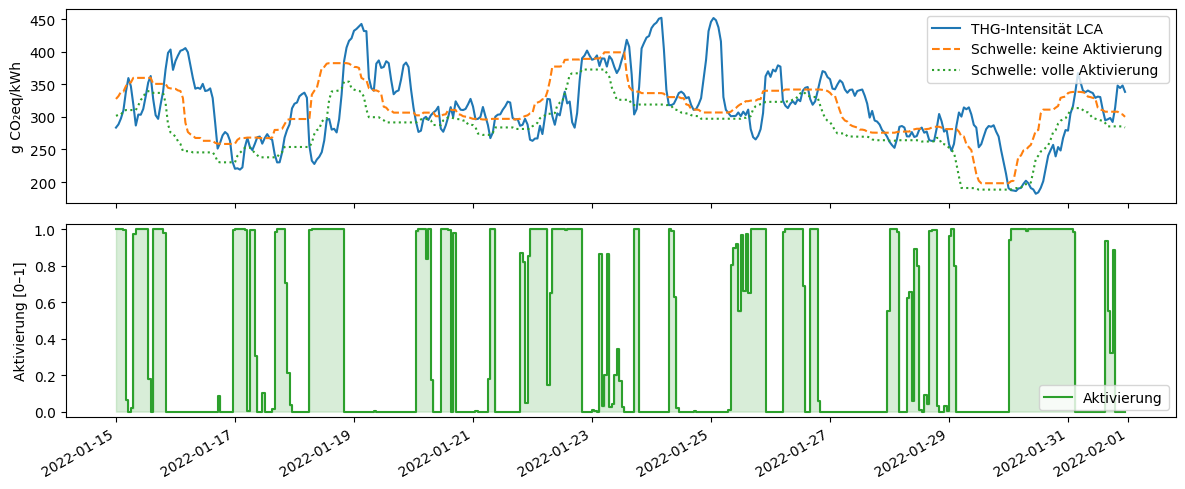

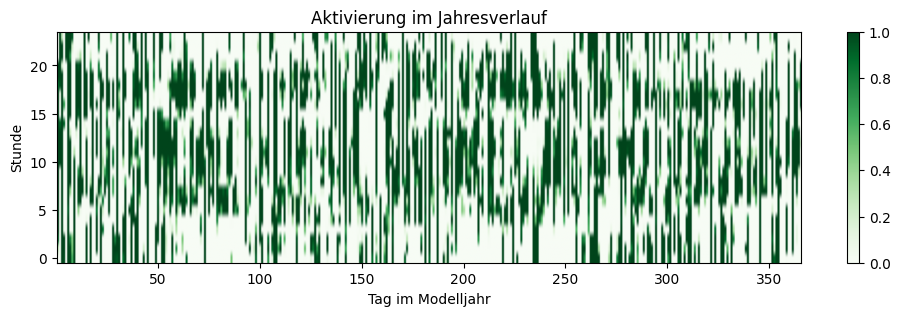

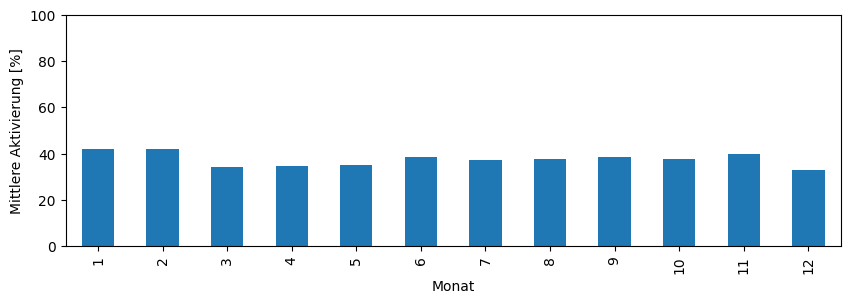

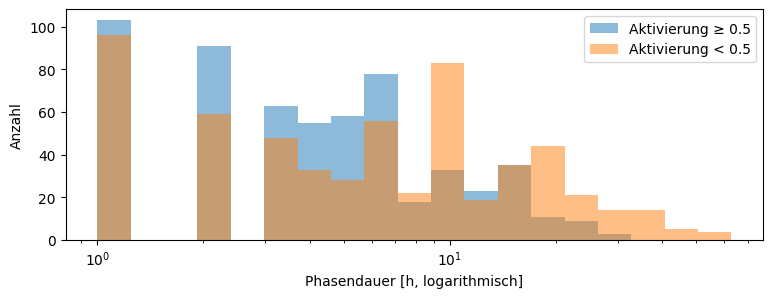

In [52]:
# EXPERIMENT C – Ausgangssignal
year = 2022
source = "co2"
method = "rolling"
window = (0,24)
activation = "sigmoid"
share = (.20,.50)  # bei binary eine Zahl, z. B. .30
threshold = (250,100)  # bei binary eine Zahl
interval = ("2022-01-15", "2022-01-31")
phase_cutoff = .5
x,low,high,base = make_signal(year,source,method,share,window,threshold,activation)
display(stats(base,phase_cutoff).round(2).to_frame("Ausgangssignal"))
visualize(x,low,high,base,source,interval,phase_cutoff)

## 2. Gebäudecharakteristik – thermische Zeitkonstante und Komfortband

Wir betrachten ein vereinfachtes thermisches Ein-Knoten-Modell für den Heizfall. Die wirksame Wärmekapazität $C$ [kWh/K] und der Wärmeverlustkoeffizient $H$ [kW/K] ergeben die Gebäudezeitkonstante

$$\tau=\frac{C}{H}.$$

Ohne Heizung, interne Gewinne und solare Gewinne bei konstanter Außentemperatur $T_a<T_{\min}$ gilt:

$$T(t)=T_a+(T_{\max}-T_a)e^{-t/\tau},\qquad t_d=\tau\ln\left(\frac{T_{\max}-T_a}{T_{\min}-T_a}\right).$$

Die Zeitkonstante $\tau$ ist daher meist wesentlich größer als die tatsächlich überbrückbare Nichtfreigabedauer $t_d$. Die nutzbare sensible Speicherkapazität ist näherungsweise $C\Delta T$ [kWh]. Bei konstanter maximaler thermischer Heizleistung $P_{\max}$ ergibt sich die Gleichgewichtstemperatur $T_{\mathrm{eq}}=T_a+P_{\max}/H$. Für $T_{\mathrm{eq}}>T_{\max}$ beträgt die Ladezeit von $T_{\min}$ bis $T_{\max}$:

$$t_c=\tau\ln\left(\frac{T_{\mathrm{eq}}-T_{\min}}{T_{\mathrm{eq}}-T_{\max}}\right).$$

Ist die Gleichgewichtstemperatur nicht größer als $T_{\max}$, lässt sich der Speicher unter diesen Annahmen nicht vollständig laden. Die Ergebnisse dienen als charakteristische Zeitmaßstäbe, nicht als Simulation des tatsächlichen Gebäudes. Die Werte sind illustrativ, keine aus PEExcel abgeleiteten Gebäudekennwerte.

,Gebäude
Zeitkonstante [h],2400.00
Ladedauer [h],12.66
Entladedauer [h],228.74
Speicherkapazität [kWh thermisch],480.00


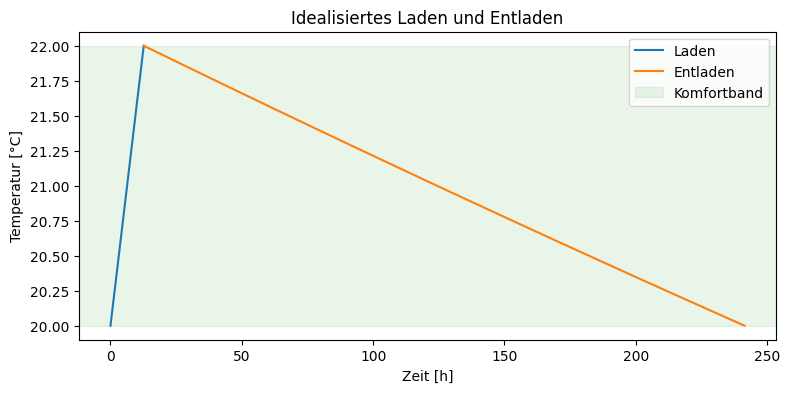

In [53]:
# EXPERIMENT C – Gebäudeparameter (absolute thermische Größen)
building = dict(C=240, H=0.1, P_max=40, T_out=0, T_min=20, comfort_band=2)
# C [kWh/K], H [kW/K], P_max [kW thermisch], Temperaturen [°C], Komfortband [K]


def building_times(C,H,P_max,T_out,T_min,comfort_band):
    if min(C,H,P_max,comfort_band)<=0 or T_out>=T_min:
        raise ValueError("Positive Parameter und T_out < T_min erforderlich (Heizfall)")
    tau=C/H; T_max=T_min+comfort_band; T_eq=T_out+P_max/H
    if T_eq<=T_max:
        raise ValueError("Heizleistung reicht nicht zur vollständigen Beladung")
    t_discharge=tau*np.log((T_max-T_out)/(T_min-T_out))
    t_charge=tau*np.log((T_eq-T_min)/(T_eq-T_max))
    return dict(tau=tau,charging_time=t_charge,discharging_time=t_discharge,capacity=C*comfort_band,T_max=T_max,T_eq=T_eq)

b = building_times(**building)
display(pd.Series({"Zeitkonstante [h]":b["tau"],"Ladedauer [h]":b["charging_time"],
                   "Entladedauer [h]":b["discharging_time"],"Speicherkapazität [kWh thermisch]":b["capacity"]}).round(2).to_frame("Gebäude"))
fig,ax=plt.subplots(figsize=(9,4))
tc=np.linspace(0,b["charging_time"],100); td=np.linspace(0,b["discharging_time"],100)
ax.plot(tc,b["T_eq"]+(building["T_min"]-b["T_eq"])*np.exp(-tc/b["tau"]),label="Laden")
ax.plot(b["charging_time"]+td,building["T_out"]+(b["T_max"]-building["T_out"])*np.exp(-td/b["tau"]),label="Entladen")
ax.axhspan(building["T_min"],b["T_max"],alpha=.1,color="tab:green",label="Komfortband")
ax.set(xlabel="Zeit [h]",ylabel="Temperatur [°C]",title="Idealisiertes Laden und Entladen"); ax.legend(); plt.show()

## 3. Zeitliche Signalverarbeitung

| Methode | Prinzip | Bezug zum Gebäude |
|---|---|---|
| `base` | Ursprüngliche Aktivierung | Referenz |
| `rolling_mean` | Rückblickender gleitender Mittelwert | Mittelungsdauer, hier aus Ladedauer abgeleitet |
| `exponential` | Exponentieller Tiefpass | Filterzeitkonstante, hier aus Entladedauer abgeleitet |
| `ramp_rate` | Begrenzte stündliche Signaländerung | Hoch- und Herunterfahren in Lade- bzw. Entladedauer |
| `lookahead` | Aktuelle Führungsgröße gegen gewichtete zukünftige Werte vergleichen | Horizont aus Entladedauer, Gewichtung nach Gebäudezeitkonstante |

Die Filterparameter sind **heuristische Zuordnungen**. Sie folgen nicht zwingend aus der Gebäudephysik: eine Glättung kann günstige Stunden verspätet aktivieren; eine Ramp-Rate ist keine physikalische Temperatur- oder Leistungsgrenze. Die Werte können im Experiment verändert werden.

**Exponentieller Filter:** $s_t=s_{t-1}+\alpha(u_t-s_{t-1})$, mit $\alpha=1-e^{-1\mathrm{h}/\tau_f}$. Dabei ist $u_t$ das Ausgangssignal und $\tau_f$ die Filterzeitkonstante.

**Zeitliche Ramp:** $s_t=s_{t-1}+\operatorname{clip}(u_t-s_{t-1},-1\mathrm{h}/t_d,1\mathrm{h}/t_c)$. Dies begrenzt die Aktivierungsänderung je Stunde, nicht die Ladeleistung selbst.

**Look-ahead:** Für die günstig orientierte Führungsgröße $z$ vergleichen wir den heutigen Stundenwert mit dem zukünftigen gewichteten Mittel. Für $k=1,\ldots,N$ gilt $w_k=e^{-k\mathrm{h}/\tau}$ und

$$v(t)=z(t)-\frac{\sum_{k=1}^{N}w_k z(t+k)}{\sum_{k=1}^{N}w_k}.$$

Je größer der Vorteil $v(t)$, desto stärker die Aktivierung. Die Umrechnung erfolgt hier über eine lineare Ramp mit zwei absoluten Vorteilsschwellen in der Originaleinheit. Negative oder kleine Vorteile sollen keine zusätzliche Aktivierung auslösen. Das letzte Intervall ohne Zukunftswerte fällt auf das Ausgangssignal zurück; davor werden nur verfügbare Zukunftsstunden verwendet.

**Wichtig:** Look-ahead nutzt bei historischen Daten perfekte Voraussicht. Reale Anwendung erfordert verfügbare Prognosen. Die Regel betrachtet weder tatsächliche Raumtemperatur noch SOC noch Bedarf oder Leistungsgrenzen und ist keine MPC. Bei Lastprognosefehlern ist auch der aktuelle Fehler erst nach Beobachtung bekannt; Look-ahead darauf wäre rein hypothetisch.

In [54]:
def process(base, x, source, kind, mean_hours, filter_tau, charging_time,
            discharging_time, horizon, weight_tau, advantage_threshold):
    if kind=="base":
        s=base.copy()
    elif kind=="rolling_mean":
        s=base.rolling(mean_hours,min_periods=1).mean()
    elif kind=="exponential":
        s=base.ewm(alpha=1-np.exp(-1/filter_tau),adjust=False).mean()
    elif kind=="ramp_rate":
        values=base.to_numpy(); out=np.empty(len(values)); out[0]=values[0]
        for i in range(1,len(out)):
            out[i]=out[i-1]+np.clip(values[i]-out[i-1],-1/discharging_time,1/charging_time)
        s=pd.Series(out,index=base.index)
    elif kind=="lookahead":
        direction=1 if info[source][2]=="high" else -1
        z=direction*x
        future=pd.concat([z.shift(-k) for k in range(1,horizon+1)],axis=1)
        weights=np.exp(-np.arange(1,horizon+1)/weight_tau)
        future_mean=future.mul(weights,axis=1).sum(axis=1)/future.notna().mul(weights,axis=1).sum(axis=1)
        advantage=z-future_mean
        a,b=advantage_threshold
        if not 0<=a<b: raise ValueError("Vorteilsschwellen: 0 <= keine < volle Aktivierung")
        s=((advantage-a)/(b-a)).clip(0,1).fillna(base)
    else:
        raise ValueError(kind)
    if source=="load_error":
        # Preserve source's negative-error restriction even after smoothing.
        s=s.where(x<0,0)
    return s.clip(0,1)


def filter_params(b, advantage_threshold, mean_factor=1, filter_factor=1, horizon_factor=1):
    return dict(mean_hours=max(1,round(b["charging_time"]*mean_factor)),
                filter_tau=b["discharging_time"]*filter_factor,
                charging_time=b["charging_time"],discharging_time=b["discharging_time"],
                horizon=max(1,round(b["discharging_time"]*horizon_factor)),
                weight_tau=b["tau"],advantage_threshold=advantage_threshold)

,Filterparameter
mean_hours,13
filter_tau,228.744432
charging_time,12.664937
discharging_time,228.744432
horizon,229
weight_tau,2400.0
advantage_threshold,"(0, 30)"


,base,rolling_mean,exponential,ramp_rate,lookahead
Mittlerer Aktivierungsgrad [%],37.50,37.50,36.62,96.03,38.92
Äquivalente Vollaktivierungsstunden [h],3285.01,3285.08,3208.00,8412.39,3409.51
Stunden mit Aktivierung > 0 [h],4259.00,7839.00,8759.00,8759.00,4318.00
"Stunden mit Aktivierung ≥ 0,9 [h]",2909.00,535.00,0.00,7808.00,2708.00
Stunden mit Aktivierung ≥ 0.5 [h],3283.00,2893.00,0.00,8753.00,3418.00
Anteil Stunden ≥ 0.5 [%],37.48,33.03,0.00,99.92,39.02
Aktivierungsphasen,580.00,197.00,0.00,1.00,335.00
Mittlere Aktivierungsdauer [h],5.66,14.69,NaN,8753.00,10.20
Median Aktivierungsdauer [h],4.00,13.00,NaN,8753.00,4.00
Mittlere Nichtaktivierungsdauer [h],9.43,29.63,8760.00,7.00,15.95


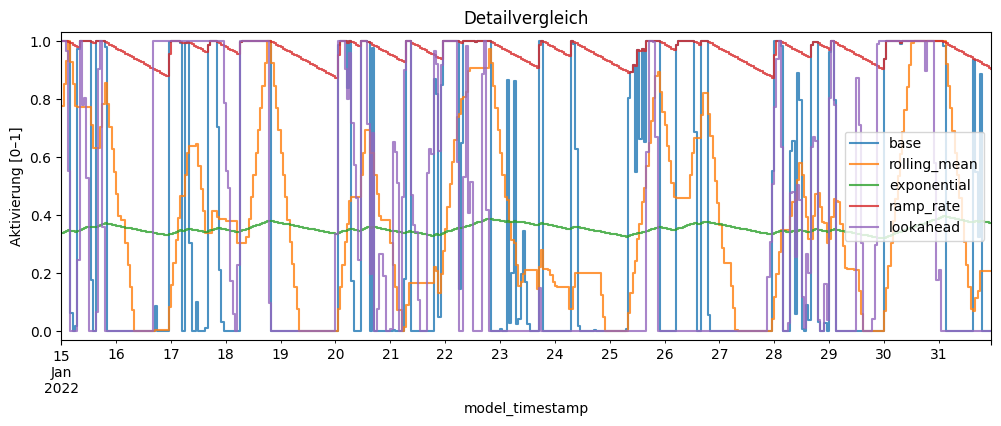

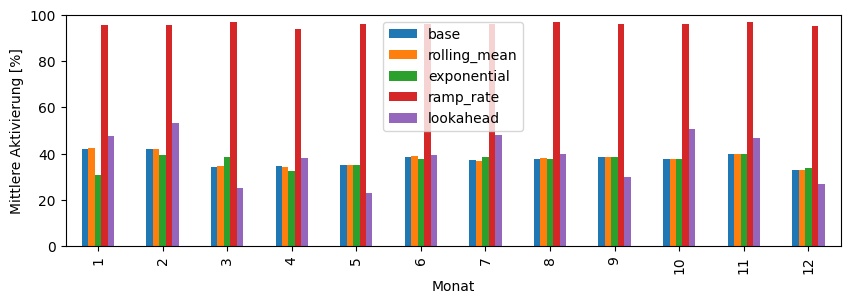

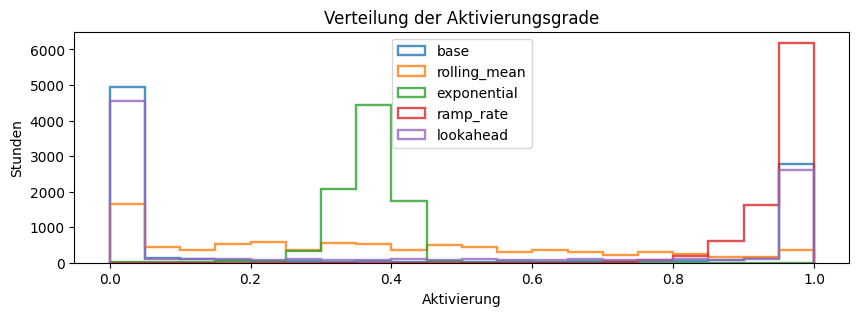

In [55]:
# EXPERIMENT C – zeitliche Verarbeitung
# Schwellen in Originaleinheit der Quelle; hier g CO₂eq/kWh Vorteil
advantage_threshold = (0,30)
mean_factor = 1.0  # Faktor auf Ladedauer
filter_factor = 1.0  # Faktor auf Entladedauer
horizon_factor = 1.0  # Faktor auf Entladedauer
kinds=["base","rolling_mean","exponential","ramp_rate","lookahead"]
params=filter_params(b,advantage_threshold,mean_factor,filter_factor,horizon_factor)
display(pd.Series(params,dtype=object).to_frame("Filterparameter"))
signals_C={kind:process(base,x,source,kind,**params) for kind in kinds}
compare(signals_C,interval,phase_cutoff)

### Auswertung C1 – hier antworten
1. Welche Operationen reduzieren kurze Aktivierungsspitzen? Bei welchen tritt eine Verzögerung auf?
2. Welche Varianten aktivieren während günstiger Stunden, welche auch danach? Vergleiche mit der ursprünglichen Führungsgröße.
3. Welche Phasendauern sind länger als die Ladedauer oder länger als die Entladedauer? Welche Konsequenzen könnten sich daraus ergeben?
4. Sind die äquivalenten Vollaktivierungsstunden ähnlich? Warum ist ein Vergleich der tatsächlich verschobenen Energie erst mit Gebäudesimulation möglich?

**Antwort:** …

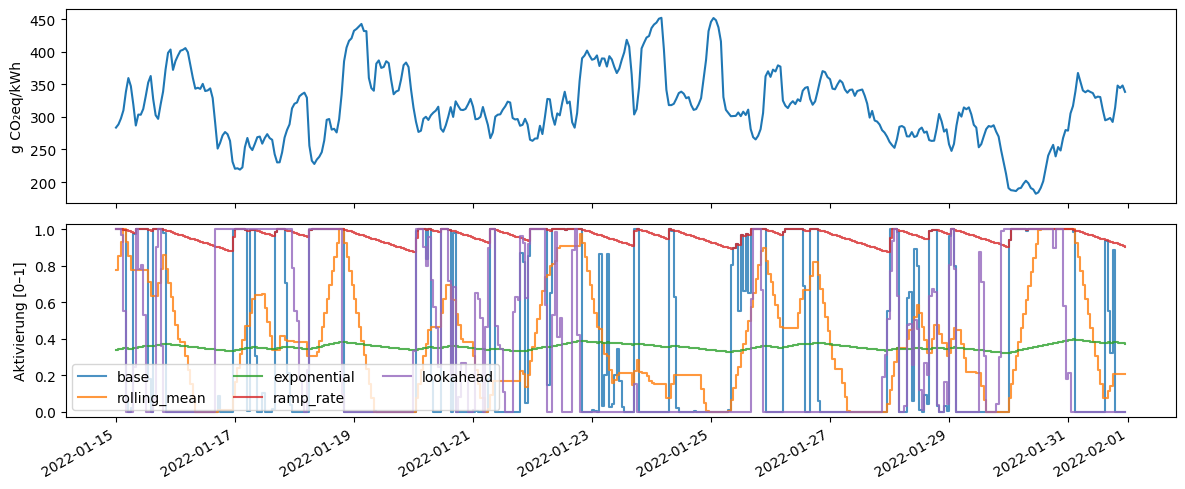

,base,rolling_mean,exponential,ramp_rate,lookahead
Aktivierungsphasen ≥ Ladedauer [%],12.1,52.3,NaN,100.0,21.2
Nichtaktivierungsphasen > Entladedauer [%],0.0,0.0,100.0,0.0,0.0


In [56]:
# Vergleich mit Führungsgröße und Zeitmaßstäben
fig,axes=plt.subplots(2,1,figsize=(12,5),sharex=True)
d=detail(x,interval)
axes[0].plot(d.index,d); axes[0].set_ylabel(info[source][1])
for name,s in signals_C.items():
    v=detail(s,interval); axes[1].step(v.index,v,where="post",label=name,alpha=.8)
axes[1].set(ylabel="Aktivierung [0–1]",ylim=(-.03,1.03)); axes[1].legend(ncol=3)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()
rows={}
for name,s in signals_C.items():
    r=periods(s,phase_cutoff)
    on=r.loc[r.state.eq(1),"hours"]; off=r.loc[r.state.eq(0),"hours"]
    rows[name]={"Aktivierungsphasen ≥ Ladedauer [%]":100*(on>=b["charging_time"]).mean(),
                "Nichtaktivierungsphasen > Entladedauer [%]":100*(off>b["discharging_time"]).mean()}
display(pd.DataFrame(rows).round(1))

## 4. Zwei Gebäude im Vergleich

Verändere die Gebäudeeigenschaften, halte das externe Signal konstant. Standardmäßig vergleichen wir ein Gebäude mit geringer und eines mit höherer wirksamer Speichermasse bei gleicher Hülle und Heizleistung. So lässt sich der Einfluss von $C$ isolieren. Du kannst anschließend auch Hülle, Komfortband oder Leistung verändern.

,Leicht,Massiv
tau,30.00,120.00
charging_time,4.29,17.17
discharging_time,4.19,16.77
capacity,180.00,720.00


,Ausgangssignal,Leicht,Massiv
Mittlerer Aktivierungsgrad [%],37.50,26.98,34.08
Äquivalente Vollaktivierungsstunden [h],3285.01,2363.86,2985.38
Stunden mit Aktivierung > 0 [h],4259.00,4464.00,4479.00
"Stunden mit Aktivierung ≥ 0,9 [h]",2909.00,1078.00,1922.00
Stunden mit Aktivierung ≥ 0.5 [h],3283.00,2206.00,2936.00
Anteil Stunden ≥ 0.5 [%],37.48,25.18,33.52
Aktivierungsphasen,580.00,748.00,531.00
Mittlere Aktivierungsdauer [h],5.66,2.95,5.53
Median Aktivierungsdauer [h],4.00,3.00,4.00
Mittlere Nichtaktivierungsdauer [h],9.43,8.75,10.95


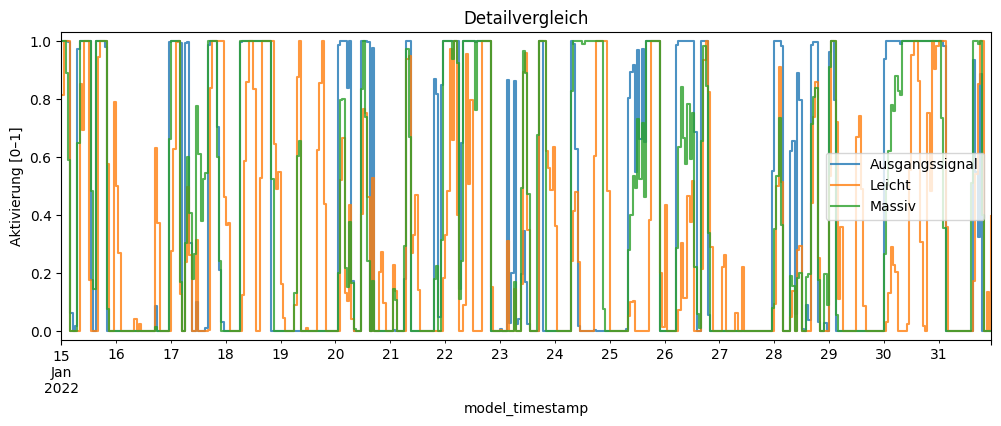

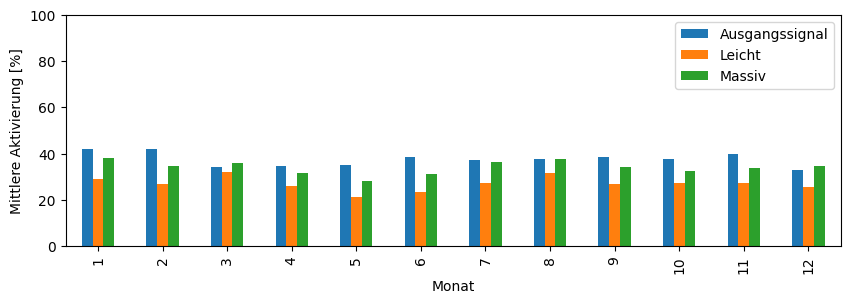

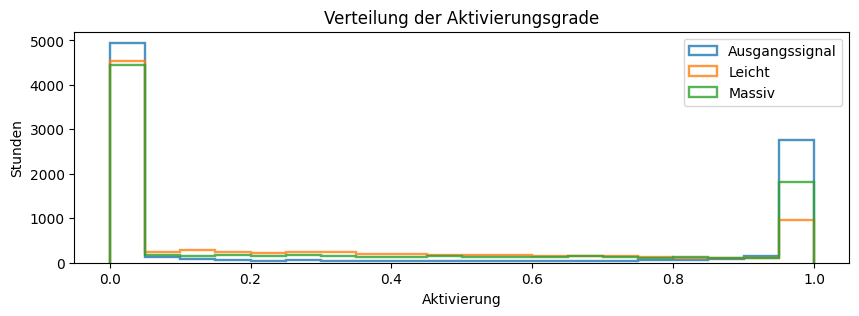

In [57]:
# EXPERIMENT C2 – Gebäudevarianten
buildings = {
    "Leicht": dict(C=60,H=2,P_max=85,T_out=0,T_min=20,comfort_band=3),
    "Massiv": dict(C=240,H=2,P_max=85,T_out=0,T_min=20,comfort_band=3),
}
selected_filter="lookahead"  # rolling_mean, exponential, ramp_rate oder lookahead
profiles={name:building_times(**v) for name,v in buildings.items()}
display(pd.DataFrame(profiles).loc[["tau","charging_time","discharging_time","capacity"]].round(2))
params_by_building={name:filter_params(v,advantage_threshold,mean_factor,filter_factor,horizon_factor) for name,v in profiles.items()}
signals_buildings={name:process(base,x,source,selected_filter,**v) for name,v in params_by_building.items()}
compare({"Ausgangssignal":base,**signals_buildings},interval,phase_cutoff)

### Auswertung C2 – hier antworten
1. Welcher Gebäudeparameter verändert sich? Wie beeinflusst er die Zeitkonstante, Lade- und Entladedauer?
2. Wie unterscheiden sich die daraus abgeleiteten Aktivierungssignale? Würde ein anderes Filterverfahren zu anderen Schlussfolgerungen führen?
3. Welche zusätzlichen Informationen wären erforderlich, um die tatsächliche Lastverschiebung, Kosten oder Emissionswirkung zu bewerten?
4. Formuliere eine überprüfbare Hypothese für PEExcel, z. B. zum Anteil des Heizstroms in günstigen Stunden, zum Komfort oder zu Lastspitzen.

**Antwort:** …

## 5. Export für die Gebäudesimulation

Exportiert wird ein kontinuierliches Aktivierungsprofil mit 8760 Stunden sowie die dokumentierte Zeitreihe und die Parameter. Das Signal kann beispielsweise einen Heizsollwert $T_{set}=T_{min}+s\Delta T$ vorgeben; der tatsächliche Verbrauch ist erst Ergebnis der Regelung. Ob kontinuierliche Werte und dieses CSV-Format in der verwendeten PEExcel-Version unterstützt werden, muss geprüft werden. Die synthetische Modellzeitachse ist noch nicht zeitzonenrichtig mit PEExcel verifiziert.

In [58]:
# EXPERIMENT – Ergebnis auswählen
selected_building="Massiv"
s=signals_buildings[selected_building]
export_signal(s,year,selected_building+"_"+selected_filter,
              dict(source=source,method=method,window=window,activation=activation,share=share,
                   threshold=threshold,filter=selected_filter,**buildings[selected_building],
                   **params_by_building[selected_building]),"signal_C")

output\signal_C_2022_Massiv_lookahead.csv – 8760 Stunden


### Schlussfolgerung und Abgabe
Dokumentiere Gebäudeparameter, Filterparameter, wichtigste Kennzahlen und deine Hypothese. Speichere das ausgeführte Notebook und das exportierte Signal. Vergleiche anschließend in PEExcel eine Referenz ohne zusätzliche Flexibilität, das Ausgangssignal aus Notebook 01 und das gebäudeangepasste Signal aus Notebook 02. Halte sonstige Eingaben konstant; prüfe Komfort, Strombedarf und Lastverlauf.